<a href="https://colab.research.google.com/github/amsalu2212/Project/blob/main/Digital%20Image%20Processing_Power%20Law(Gamma)%20Transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Name: Amsalu Tessema Adgeh**
# **ID Number: 2026A8000929002**
# **Digital Image processing Assignment-1**

# **Problem 1  Power-Law (Gamma) Transformation**
1) For a given input grayscale image, we first load the image into memory using
the image reading function imread. Assuming that the matrix elements storing
the image are of data type uint8, please design an algorithm to perform power
law transformation on the image. Implement this function using MATLAB code
and provide a test MATLAB code.

#**Answer:**

The power-law transformation, also called gamma transformation, is $$ s = c r^\gamma $$
where:
\(r\) = input pixel intensity
\(s\) = output pixel intensity
\(c\) = scaling constant
\(\gamma\) = gamma parameter

For an 8-bit grayscale image:

$$ 0\leq r\leq255 $$

It is convenient to normalize the intensity:

$$ r_n=\frac{r}{255} $$

Then:

$$ s_n=c r_n^\gamma $$

and convert the result back to the 8-bit range:

$$ s=255s_n $$

For simplicity, we normally use:

$$ c=1 $$

so:

$$ s=255\left(\frac{r}{255}\right)^\gamma $$
Effect of gamma
Gamma	Effect
\(0<\gamma<1\)	Brightens darker regions
\(\gamma=1\)	No change
\(\gamma>1\)	Darkens the image
Very small \(\gamma\)	Strong brightening
Large \(\gamma\)	Strong darkening

In [1]:
# First install and import all required libraries
!pip install opencv-python-headless ipywidgets --quiet

import numpy as np
import cv2
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Checkbox, Button, VBox, HBox, Output
from IPython.display import display, clear_output
import urllib.request

import os

print("All libraries loaded.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 50.5 MB/s eta 0:00:00
All libraries loaded.


Saving IMG_20260906_093555.jpg to IMG_20260906_093555.jpg
Image shape: (1800, 4000)
Data type: uint8
Min/Max pixel value: 0 255


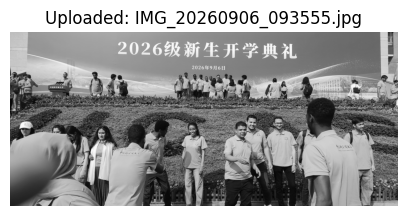

In [2]:
#Then we can upload our own image
from google.colab import files

uploaded = files.upload()          # a file-picker dialog appears
img_path = list(uploaded.keys())[0]
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

print("Image shape:", img.shape)
print("Data type:", img.dtype)
print("Min/Max pixel value:", img.min(), img.max())

plt.figure(figsize=(5,5))
plt.imshow(img, cmap='gray')
plt.title(f'Uploaded: {img_path}')
plt.axis('off')
plt.show()

In [3]:
# Then we will define power-law (gamma) transformation function
def power_law_transform(img, gamma, c=1.0):
    """ Apply power-law (gamma) transformation to a grayscale image.

    Parameters
    ----------
    img   : np.ndarray (uint8) — input grayscale image
    gamma : float — gamma value
    c     : float — scaling constant (default = 1.0)

    Returns
    -------
    out : np.ndarray (uint8) — transformed image
    """
    # Step 1: Normalize to [0, 1]
    img_norm = img.astype(np.float32) / 255.0

    # Step 2: Apply s = c * r^gamma
    out = c * np.power(img_norm, gamma)

    # Step 3: Clip to [0,1] and convert back to uint8
    out = np.clip(out, 0, 1)
    return (out * 255).astype(np.uint8)

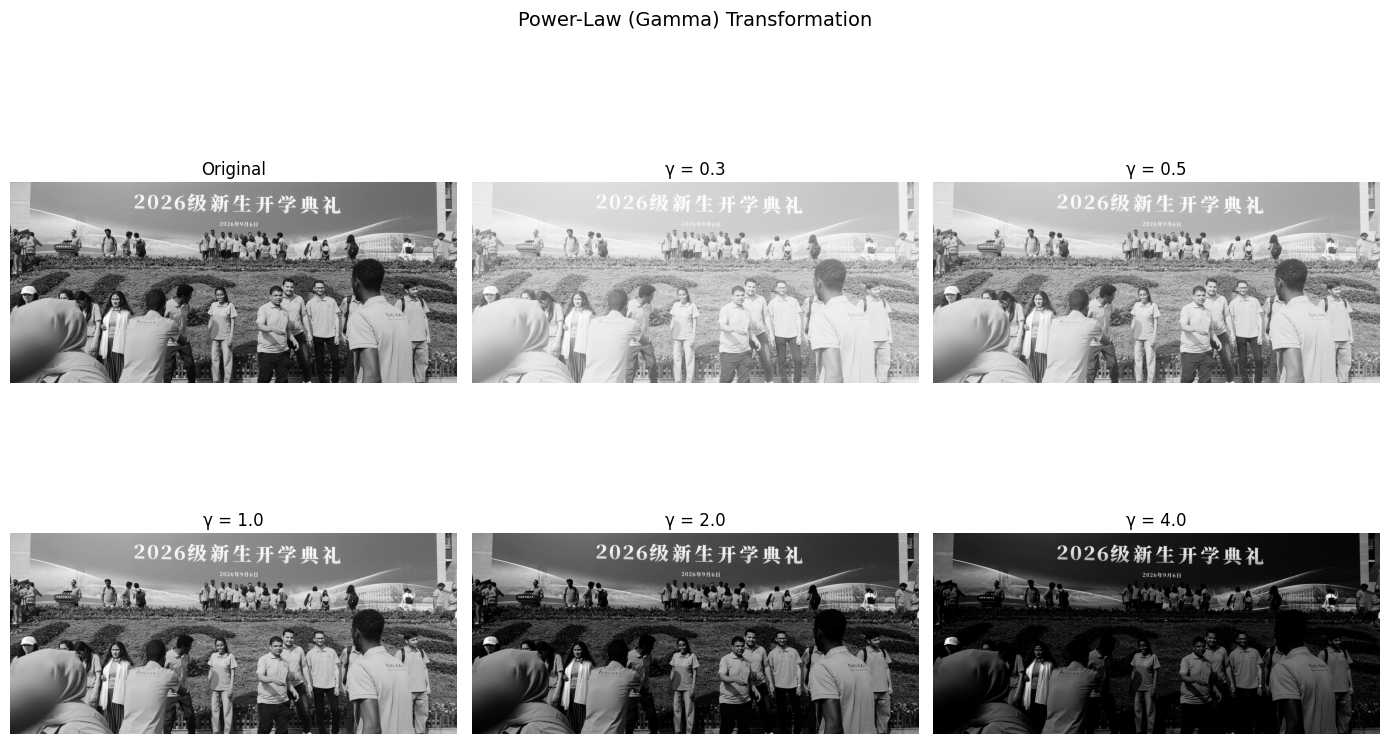

In [4]:
# Then we can test with different gamma values and see the result
gammas = [0.3, 0.5, 1.0, 2.0, 4.0]
c = 1.0

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

# Original
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

# Transform for each gamma
for i, g in enumerate(gammas):
    out = power_law_transform(img, g, c)
    axes[i+1].imshow(out, cmap='gray')
    axes[i+1].set_title(f'γ = {g}')
    axes[i+1].axis('off')

plt.suptitle('Power-Law (Gamma) Transformation', fontsize=14)
plt.tight_layout()
plt.savefig('problem1_power_law.png', dpi=150)
plt.show()

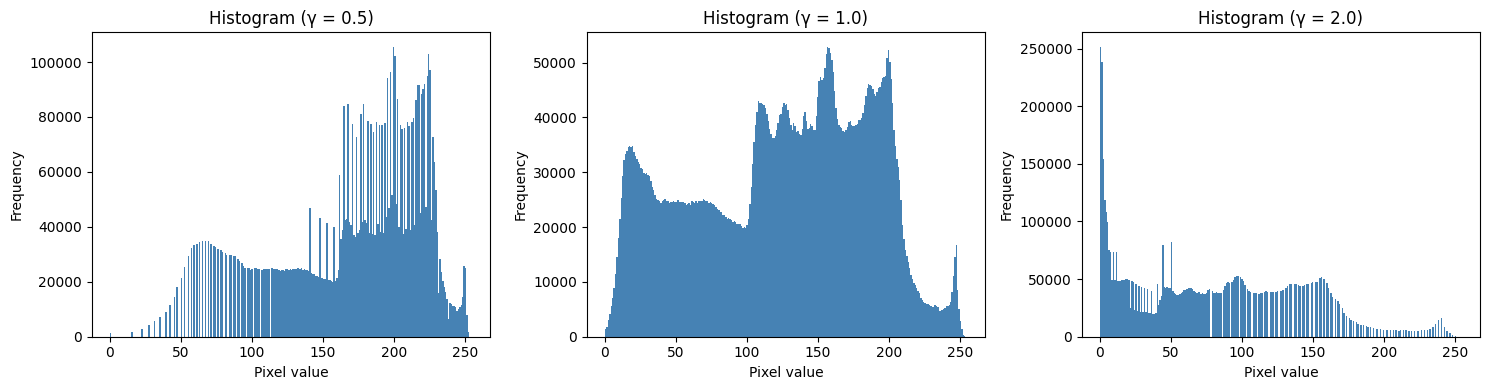

In [5]:
# Then we can compare histograms for γ=0.5, 1.0, 2.0
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, g in zip(axes, [0.5, 1.0, 2.0]):
    out = power_law_transform(img, g)
    ax.hist(out.ravel(), bins=256, range=(0,255), color='steelblue')
    ax.set_title(f'Histogram (γ = {g})')
    ax.set_xlabel('Pixel value'); ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('problem1_histograms.png', dpi=150)
plt.show()

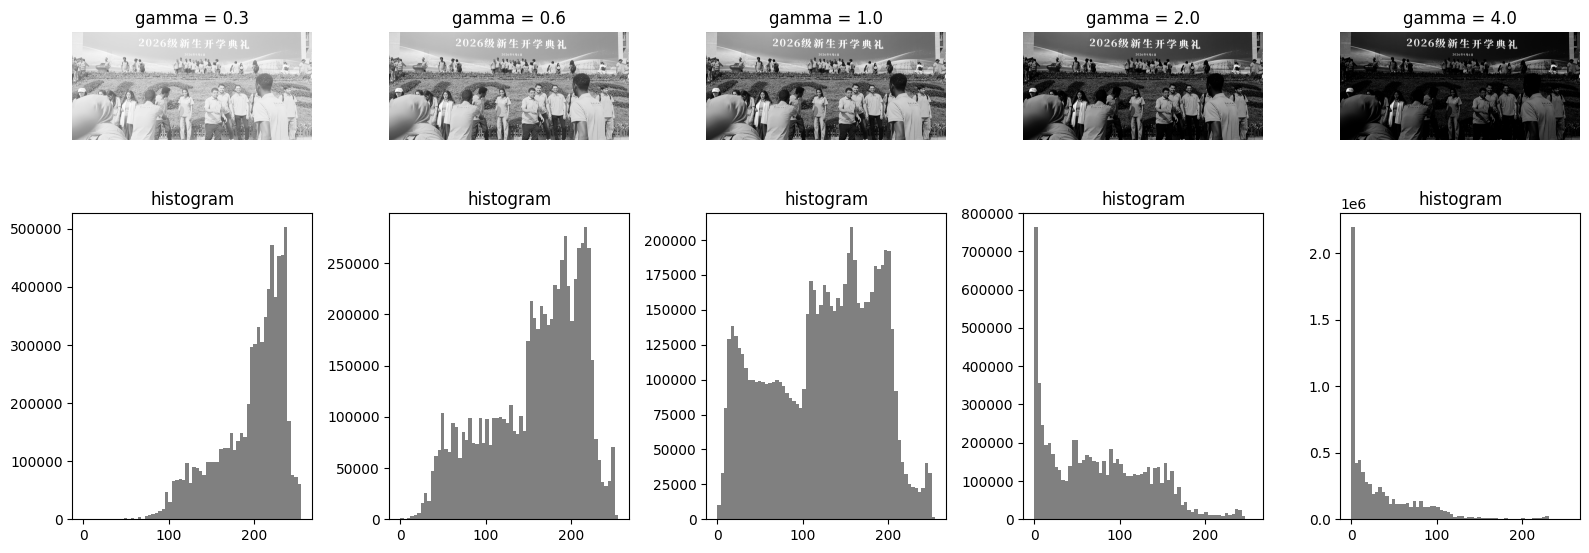

{0.3: 197.2, 0.6: 158.8, 1.0: 124.5, 2.0: 75.3, 4.0: 35.5}


In [11]:
gammas = [0.3, 0.6, 1.0, 2.0, 4.0]
fig, ax = plt.subplots(2, len(gammas), figsize=(16, 6.4))
for i, g in enumerate(gammas):
    out = power_law_transform(img, g)
    ax[0, i].imshow(out, cmap="gray", vmin=0, vmax=255)
    ax[0, i].set_title(f"gamma = {g}"); ax[0, i].axis("off")
    ax[1, i].hist(out.ravel(), bins=64, range=(0, 255), color="gray")
    ax[1, i].set_title("histogram")
plt.tight_layout(); plt.show()
print({g: round(float(power_law_transform(img, g).mean()), 1) for g in gammas})